# Healthcare Operations Cost Analysis: analysis notebook

This notebook walks through the analysis step by step. The logic lives in `python/analysis.py`, so the notebook and the
`make analyze` script always produce the same numbers. Run `make ingest transform` first to build `data/healthcare.duckdb`.

**Questions**
- **0. Context:** where do Medicare inpatient dollars go?
- **a.** Which cost components and hospital characteristics drive payment per discharge and MSPB?
- **b.** How much do excess readmissions cost, and which conditions and segments drive it?
- **c.** Do high-volume hospitals differ from low-volume ones on readmissions?
- **d.** What would a 10% cut in excess readmissions at the top-N hospitals save?

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'python'))
import pandas as pd
from IPython.display import Image, display, Markdown
import analysis as A
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
pd.set_option('display.max_colwidth', 70)
t = A.load_tables()
{k: v.shape for k, v in t.items()}

{'mart_hospital': (5495, 54),
 'mart_hospital_condition': (18330, 27),
 'mart_state_summary': (56, 14),
 'int_drg_national': (540, 12),
 'mart_cost_drivers': (17, 6),
 'stg_mspb_by_claim': (63646, 9)}

## Data quality summary
The full report is in `reports/data_quality.md`. The join match rates are below.

In [2]:
import duckdb
con = duckdb.connect(str(A.DB_PATH), read_only=True)
dq = con.execute((ROOT / 'sql/quality/03_dq_join_match_rates.sql').read_text()).df()
con.close()
dq

,join_path,base_hospitals,matched,match_pct
0,Inpatient -> General Info,2906,2854,98.2000
1,Inpatient -> HRRP (any row),2906,2883,99.2000
2,Inpatient -> HRRP (>=1 scored ERR),2906,2789,96.0000
3,Inpatient -> MSPB (scored),2906,2787,95.9000
4,Inpatient -> all three others,2906,2704,93.0000
5,HRRP -> Inpatient,3055,2883,94.4000
6,MSPB (scored) -> Inpatient,2856,2787,97.6000
7,General Info (acute care) -> Inpatient,3094,2854,92.2000
8,HRRP condition rows -> DRG payment at same hospital,18330,10414,56.8000


## 0. Context: where Medicare inpatient money goes

In [3]:
ctx = A.cost_context(t)
print(f"Total Medicare inpatient payments: {A.money(ctx['total_medicare_inpatient_payment'], 2)} "
      f"over {ctx['total_discharges']:,} discharges ({A.money(ctx['national_payment_per_discharge'])}/discharge)")
print(f"Top DRG {ctx['top_drg']['code']} ({ctx['top_drg']['desc']}): {ctx['top_drg']['share']:.1%} of spend")
print(f"Top 10 DRGs: {ctx['top10_drg_share']:.1%}; {ctx['drgs_for_50pct_of_spend']} DRGs = 50% of spend")
print('Variance decomposition of log payment per discharge:', {k: round(v, 3) for k, v in ctx['variance_decomposition'].items()})
ctx['top_drgs']

Total Medicare inpatient payments: $75.11B over 4,952,481 discharges ($15.2K/discharge)
Top DRG 871 (SEPTICEMIA OR SEVERE SEPSIS WITHOUT MV >96 HOURS WITH MCC): 11.9% of spend
Top 10 DRGs: 33.7%; 25 DRGs = 50% of spend
Variance decomposition of log payment per discharge: {'share_case_mix': 0.511, 'share_price': 0.486, 'share_covariance': 0.003, 'contribution_case_mix': 0.513, 'contribution_price': 0.487}


,drg_code,drg_desc,discharges,medicare_payment,avg_medicare_payment,share_of_medicare_payment,cumulative_share
0,871,SEPTICEMIA OR SEVERE SEPSIS WITHOUT MV >96 HOURS WITH MCC,"577,119.0000","8,959,316,640.0047","15,524.2102",0.1193,0.1193
1,853,INFECTIOUS AND PARASITIC DISEASES WITH O.R. PROCEDURES WITH MCC,"79,560.0000","3,226,700,445.9993","40,556.8181",0.0430,0.1622
2,291,HEART FAILURE AND SHOCK WITH MCC,"304,694.0000","3,053,746,234.9965","10,022.3379",0.0407,0.2029
3,177,RESPIRATORY INFECTIONS AND INFLAMMATIONS WITH MCC,"141,351.0000","1,790,617,727.9999","12,667.8816",0.0238,0.2267
4,267,ENDOVASCULAR CARDIAC VALVE REPLACEMENT AND SUPPLEMENT PROCEDURES W...,"39,606.0000","1,606,686,527.9999","40,566.7456",0.0214,0.2481
5,274,PERCUTANEOUS AND OTHER INTRACARDIAC PROCEDURES WITHOUT MCC,"58,174.0000","1,439,721,311.0017","24,748.5356",0.0192,0.2673
6,003,ECMO OR TRACHEOSTOMY WITH MV >96 HOURS OR PRINCIPAL DIAGNOSIS EXCE...,"6,749.0000","1,414,452,428.0010","209,579.5567",0.0188,0.2861
7,193,SIMPLE PNEUMONIA AND PLEURISY WITH MCC,"136,649.0000","1,348,415,170.0008","9,867.7280",0.0180,0.3041
8,266,ENDOVASCULAR CARDIAC VALVE REPLACEMENT AND SUPPLEMENT PROCEDURES W...,"23,630.0000","1,252,267,566.0005","52,994.8187",0.0167,0.3207
9,870,SEPTICEMIA OR SEVERE SEPSIS WITH MV >96 HOURS,"20,906.0000","1,228,811,341.9994","58,777.9270",0.0164,0.3371


In [4]:
ctx['mspb_components'].head(8)

,national_avg_spend_per_episode,share_of_national_episode_spend,share_of_cross_hospital_variation
component,,,
Index stay: Inpatient,"12,477.0000",0.4541,0.4848
Post-discharge: Inpatient,"4,316.0000",0.1571,0.2249
Post-discharge: Skilled Nursing Facility,"4,194.0000",0.1526,0.0811
Post-discharge: Carrier,"1,653.0000",0.0602,0.0547
Index stay: Carrier,"1,546.0000",0.0563,0.1012
Post-discharge: Outpatient,"1,061.0000",0.0386,0.0107
Pre-admission: Carrier,785.0000,0.0286,0.0190
Post-discharge: Home Health Agency,758.0000,0.0276,0.0071


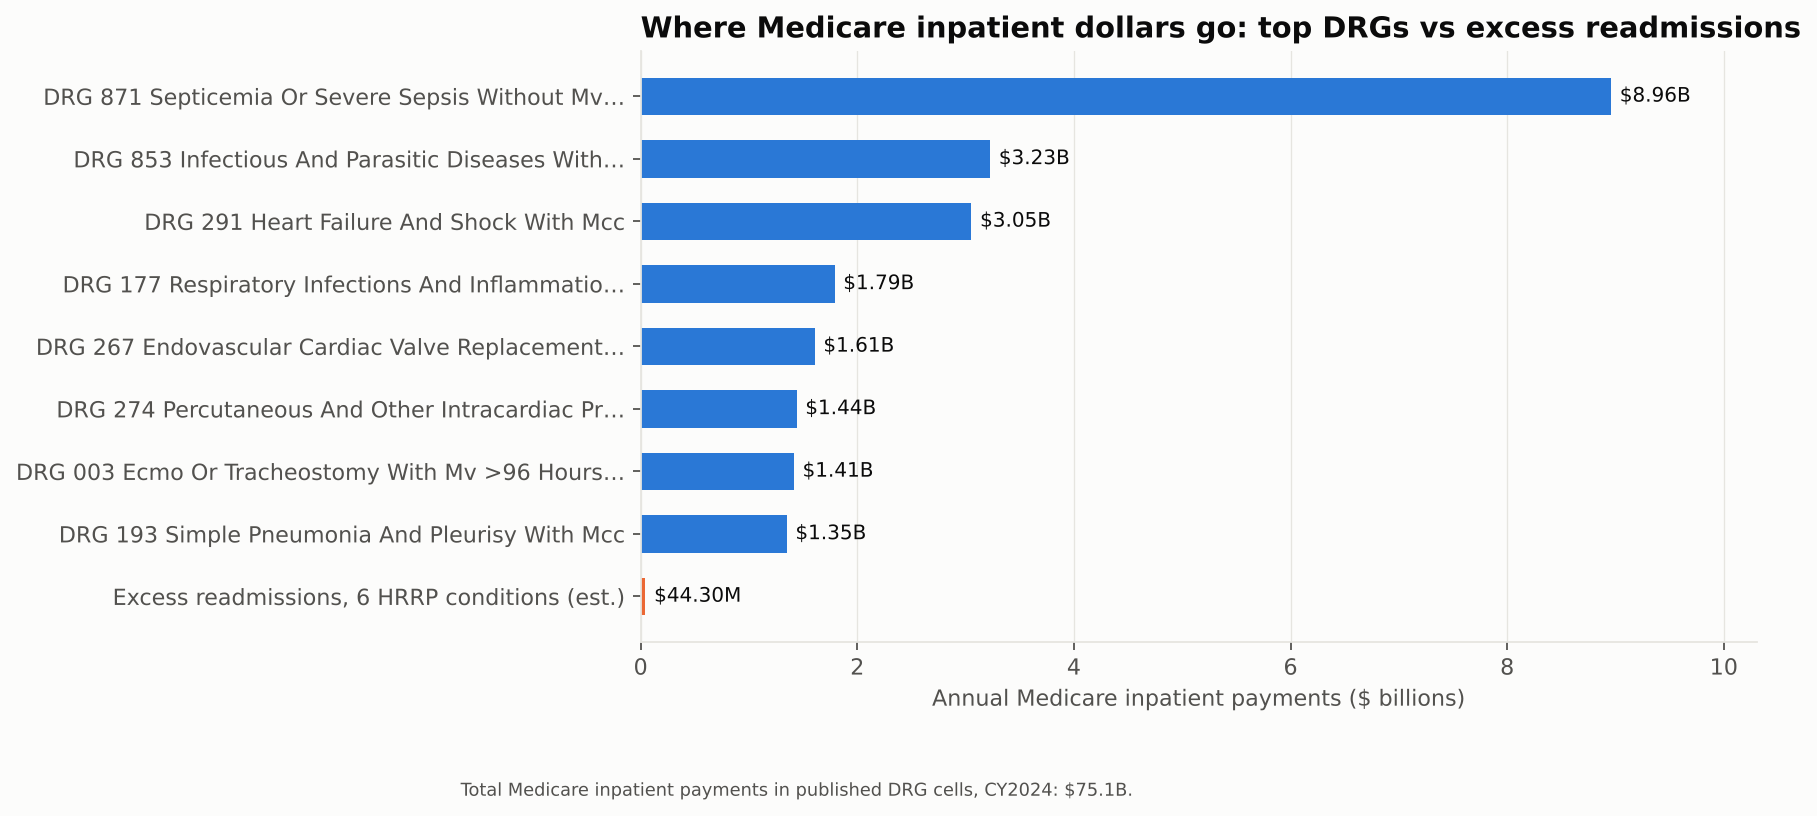

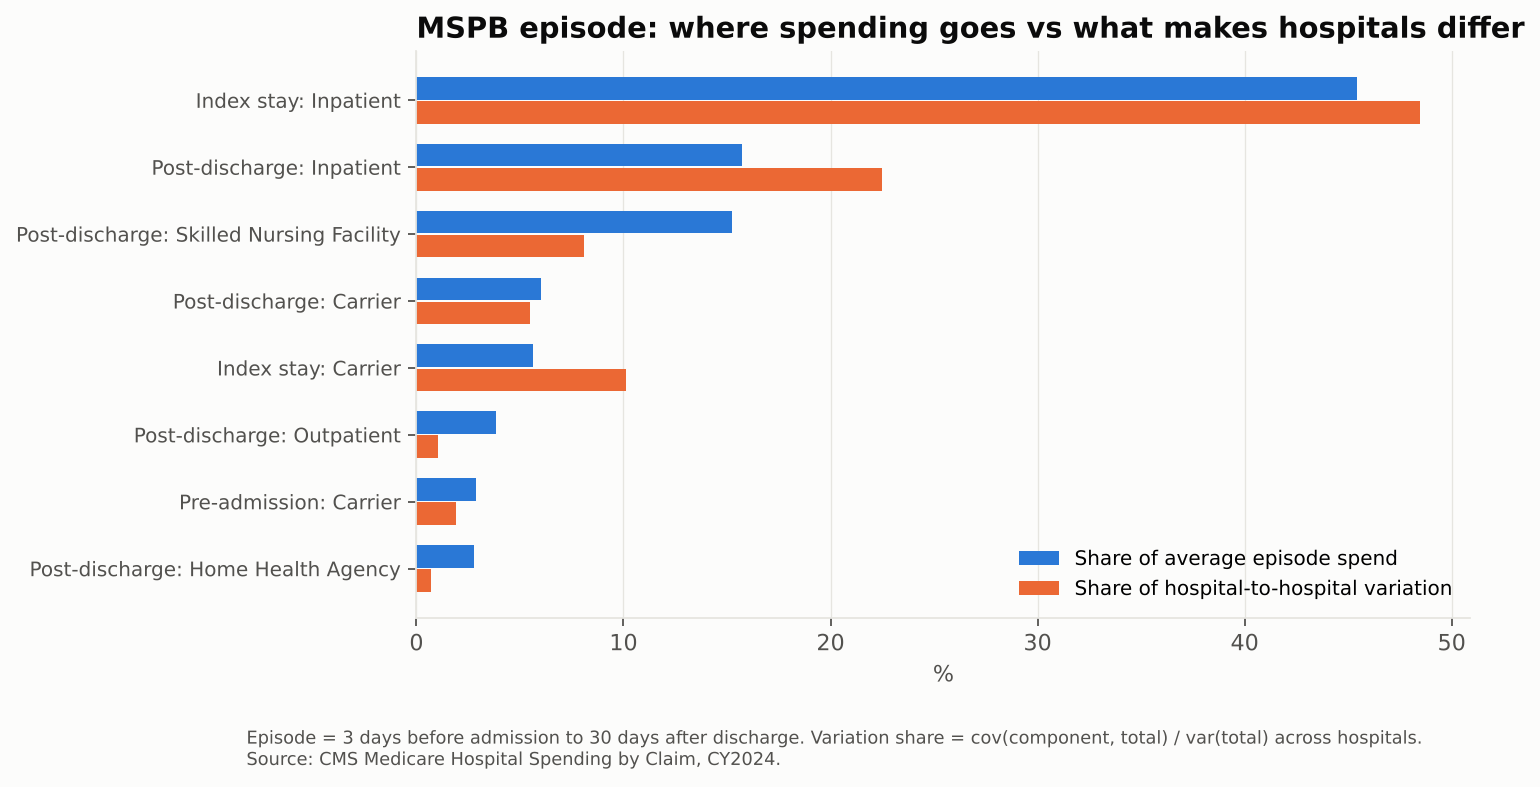

In [5]:
display(Image(ROOT / 'reports/figures/cost_drivers_context.png'))
display(Image(ROOT / 'reports/figures/mspb_components.png'))

## a. Regression: drivers of payment per discharge and MSPB
OLS with heteroskedasticity-robust (HC3) standard errors. `ppd_base` uses exactly the requested predictors. `ppd_casemix` adds
the hospital's case-mix index (its DRG mix) and urban/rural location. The outcome is log payment per discharge, so
`pct_effect` is the % difference versus the reference group (Small, Non-profit, South).

In [6]:
reg = A.run_regressions(t)
for k in ['ppd_base', 'ppd_casemix', 'mspb_base', 'mspb_casemix']:
    print(f"{k:13s} n={reg[k]['n']:,}  R2={reg[k]['r2']:.3f}  adjR2={reg[k]['adj_r2']:.3f}")
reg['ppd_base']['table']

ppd_base      n=2,594  R2=0.259  adjR2=0.256
ppd_casemix   n=2,594  R2=0.642  adjR2=0.641
mspb_base     n=2,544  R2=0.137  adjR2=0.133
mspb_casemix  n=2,544  R2=0.162  adjR2=0.158


,coef,std_err,p_value,ci_low,ci_high,pct_effect,pct_ci_low,pct_ci_high
Intercept,9.3435,0.0249,0.0000,9.2948,9.3922,"1,142,361.6922","1,088,048.3315","1,199,386.0263"
"Size: Large (2,000-4,999)",0.1792,0.0165,0.0000,0.1469,0.2115,19.6306,15.8287,23.5572
"Size: Medium (500-1,999)",0.0239,0.0140,0.0879,-0.0035,0.0514,2.4206,-0.3543,5.2729
"Size: Very large (5,000+)",0.3556,0.0239,0.0000,0.3087,0.4025,42.7016,36.1668,49.5501
Ownership: For-profit,0.0111,0.0153,0.4674,-0.0188,0.0411,1.1165,-1.8667,4.1904
Ownership: Government,0.0903,0.0230,0.0001,0.0451,0.1354,9.4461,4.6141,14.5013
Region: Midwest,0.0289,0.0146,0.0487,0.0002,0.0576,2.9282,0.0159,5.9254
Region: Northeast,0.1403,0.0197,0.0000,0.1018,0.1789,15.0647,10.7128,19.5877
Region: West,0.3282,0.0160,0.0000,0.2969,0.3595,38.8515,34.5730,43.2660
Star rating (+1 star),-0.0315,0.0064,0.0000,-0.0441,-0.0189,-3.1027,-4.3134,-1.8766


In [7]:
reg['ppd_casemix']['table']

,coef,std_err,p_value,ci_low,ci_high,pct_effect,pct_ci_low,pct_ci_high
Intercept,9.6702,0.0178,0.0000,9.6353,9.7050,"1,583,682.8191","1,529,387.8556","1,639,905.1880"
"Size: Large (2,000-4,999)",-0.0510,0.0143,0.0004,-0.0790,-0.0230,-4.9726,-7.5959,-2.2749
"Size: Medium (500-1,999)",-0.0478,0.0117,0.0000,-0.0707,-0.0249,-4.6688,-6.8255,-2.4622
"Size: Very large (5,000+)",-0.0365,0.0185,0.0485,-0.0727,-0.0002,-3.5824,-7.0143,-0.0239
Ownership: For-profit,-0.0529,0.0100,0.0000,-0.0724,-0.0334,-5.1556,-6.9886,-3.2865
Ownership: Government,0.1007,0.0180,0.0000,0.0655,0.1359,10.5894,6.7647,14.5511
Region: Midwest,0.0072,0.0098,0.4636,-0.0121,0.0265,0.7233,-1.1994,2.6834
Region: Northeast,0.1618,0.0137,0.0000,0.1350,0.1887,17.5645,14.4499,20.7639
Region: West,0.2252,0.0123,0.0000,0.2011,0.2494,25.2631,22.2765,28.3227
Location: Urban,-0.0285,0.0121,0.0183,-0.0522,-0.0048,-2.8119,-5.0880,-0.4811


In [8]:
pd.DataFrame({k: reg[k]['unique_r2'] for k in ['ppd_base', 'ppd_casemix', 'mspb_base', 'mspb_casemix']})

,ppd_base,ppd_casemix,mspb_base,mspb_casemix
Case mix (DRG mix),NaN,0.3726,NaN,0.0006
Ownership,0.0074,0.0158,0.0218,0.0159
Readmission ratio,0.0105,0.0001,0.0003,0.0000
Region,0.1361,0.0752,0.0216,0.0233
Size band,0.1001,0.0034,0.0348,0.0068
Star rating,0.0078,0.0062,0.0308,0.0355
Urban/rural,NaN,0.0010,NaN,0.0214


In [9]:
reg['mspb_base']['table']

,coef,std_err,p_value,ci_low,ci_high
Intercept,1.0278,0.0070,0.0000,1.0140,1.0415
"Size: Large (2,000-4,999)",0.0378,0.0042,0.0000,0.0296,0.0461
"Size: Medium (500-1,999)",0.0241,0.0041,0.0000,0.0161,0.0321
"Size: Very large (5,000+)",0.0410,0.0048,0.0000,0.0316,0.0504
Ownership: For-profit,0.0296,0.0048,0.0000,0.0203,0.0390
Ownership: Government,-0.0070,0.0047,0.1359,-0.0162,0.0022
Region: Midwest,-0.0302,0.0036,0.0000,-0.0373,-0.0231
Region: Northeast,-0.0044,0.0043,0.3045,-0.0129,0.0040
Region: West,-0.0156,0.0049,0.0016,-0.0252,-0.0059
Star rating (+1 star),-0.0150,0.0016,0.0000,-0.0182,-0.0118


### Regression diagnostics

In [10]:
pd.DataFrame({k: {kk: vv for kk, vv in reg[k]['diagnostics'].items() if kk != 'vif'} for k in ['ppd_base','ppd_casemix','mspb_base','mspb_casemix']})

,ppd_base,ppd_casemix,mspb_base,mspb_casemix
n,"2,594.0000","2,594.0000","2,544.0000","2,544.0000"
max_vif,1.4109,1.8180,1.4032,1.8049
breusch_pagan_p,0.0000,0.0000,0.0000,0.0000
jarque_bera_p,0.0000,0.0000,0.0000,0.0000
resid_skew,1.2415,1.9123,0.9446,1.0002
resid_kurtosis,7.3655,14.8762,6.4926,6.6747
influential_points_cooks_gt_4_over_n,156.0000,118.0000,113.0000,117.0000
r2_without_influential_points,0.3538,0.7513,0.1785,0.2248
condition_number,18.2789,24.3407,18.3003,24.3610


State fixed-effects R2: 0.769 | star rating as categories R2: 0.643


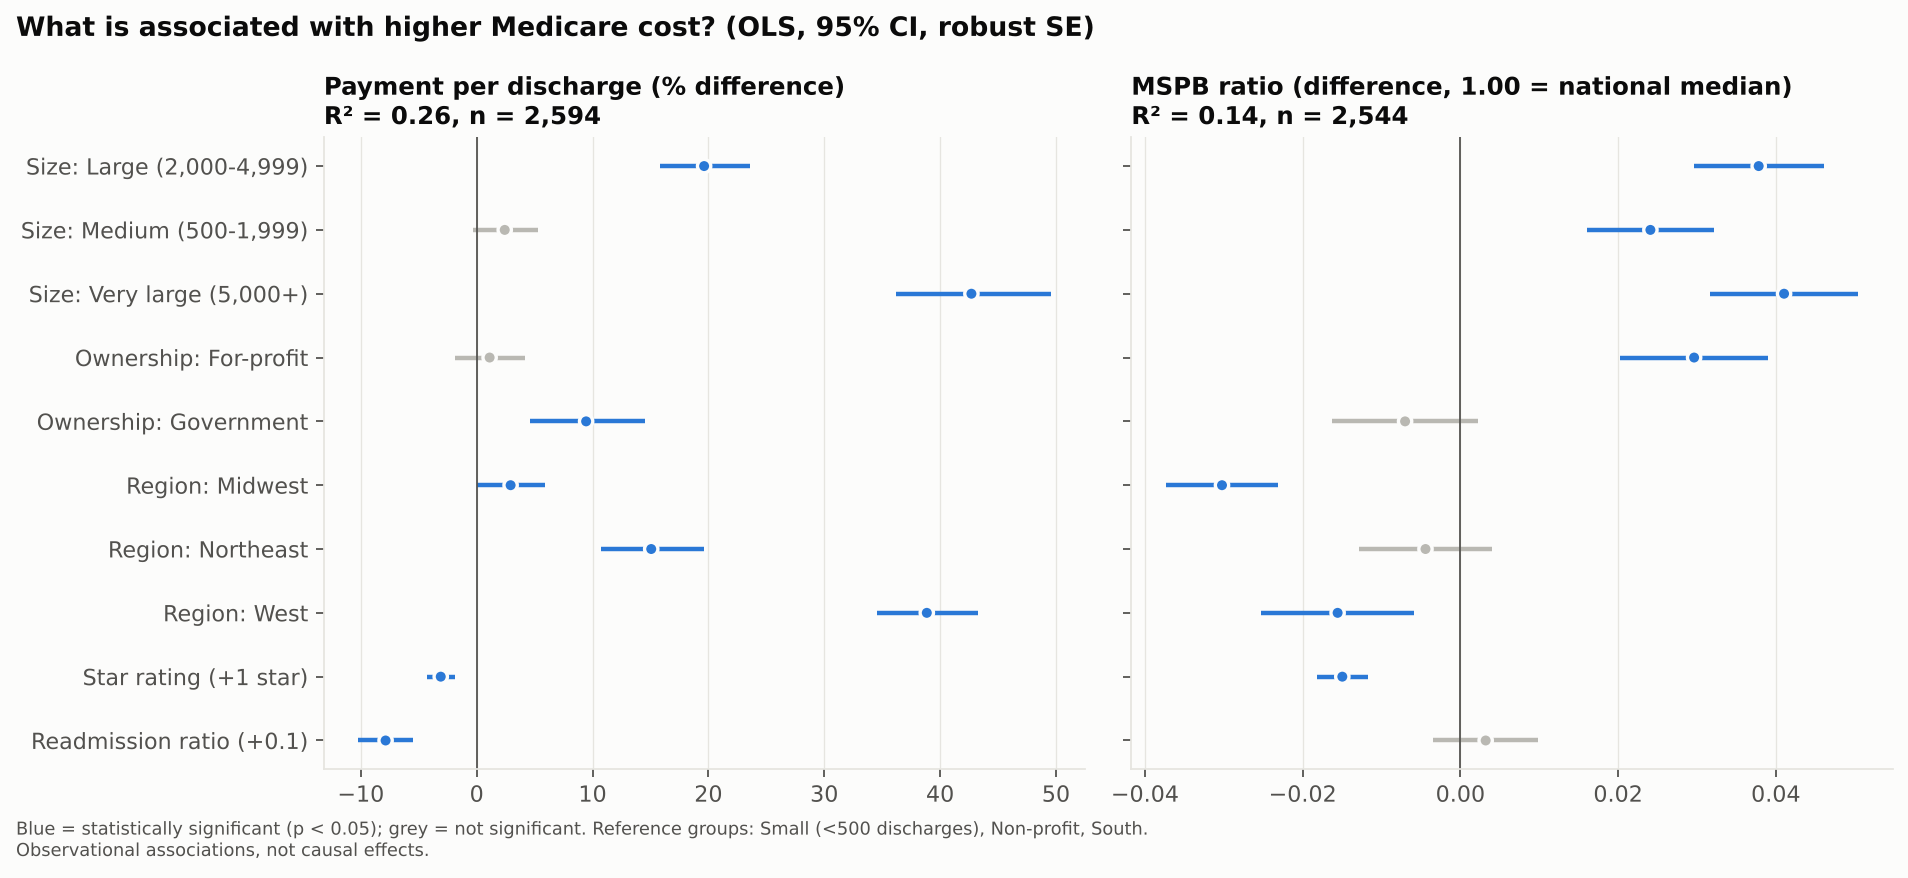

In [11]:
print('State fixed-effects R2:', round(reg['ppd_casemix_state_fe_r2'], 3), '| star rating as categories R2:', round(reg['ppd_casemix_star_categorical_r2'], 3))
display(Image(ROOT / 'reports/figures/regression_coefficients.png'))

## b. Cost of excess readmissions
`excess readmissions = (predicted rate - expected rate) x eligible discharges`, divided by the 3-year HRRP period to get an
annual figure. This is multiplied by the average payment for the condition's DRGs (low, base and high assumptions). Only
hospitals performing worse than expected (positive excess) count toward the cost.

In [12]:
b = A.excess_readmission_costs(t)
print(f"Annual excess readmission cost: base {A.money(b['total_cost_base'])} (low {A.money(b['total_cost_low'])}, high {A.money(b['total_cost_high'])})")
print(f"= {b['share_of_inpatient_payments']:.3%} of Medicare inpatient payments; incl. suppressed-cell upper bound {b['share_of_inpatient_payments_incl_suppressed_ub']:.3%}")
print(f"Positive excess readmissions/yr: {b['positive_excess_readmissions_per_year']:,.0f}; net across all hospitals: {b['net_excess_readmissions_per_year']:,.0f}")
print(f"Rows with published counts: {b['rows_with_counts']:,} / {b['rows_total']:,}")
b['by_condition']

Annual excess readmission cost: base $44.3M (low $30.5M, high $53.7M)
= 0.059% of Medicare inpatient payments; incl. suppressed-cell upper bound 0.065%
Positive excess readmissions/yr: 4,082; net across all hospitals: 321
Rows with published counts: 8,037 / 18,330


,hospitals_with_counts,eligible_discharges_per_year,hospitals_err_above_1,net_excess_readmissions_per_year,positive_excess_readmissions_per_year,cost_low,cost_base,cost_high,avg_cost_per_excess_readmission,share_of_excess_cost
Heart failure,2316,"286,272.3333",1187,-93.1109,"1,618.7148","11,441,153.8159","15,871,578.7814","18,970,521.1045","9,805.0497",0.3583
Pneumonia,2320,"270,636.0000",1189,391.0848,"1,508.4894","9,564,979.8455","15,836,023.5298","19,023,919.3678","10,497.9348",0.3575
CABG surgery,363,"21,716.0000",221,9.1764,113.6408,"3,516,017.6141","4,464,395.9972","5,614,964.4962","39,285.1524",0.1008
Heart attack (AMI),1240,"89,420.0000",703,17.6840,376.8184,"2,391,686.4954","3,901,663.0322","4,810,028.3639","10,354.2253",0.0881
COPD,1545,"74,831.0000",879,128.1622,357.2420,"2,227,014.4351","2,793,953.7092","3,519,730.5870","7,820.8992",0.0631
Hip/knee replacement,253,"35,763.6667",136,-131.7443,106.9245,"1,356,872.9426","1,434,076.4733","1,720,437.6166","13,412.0522",0.0324


In [13]:
for dim, g in b['segments'].items():
    display(Markdown(f'**By {dim}**')); display(g)

**By size_band**

,hospitals,eligible_discharges_per_year,positive_excess_readmissions,excess_cost_base,share_of_excess_cost,excess_cost_per_1000_discharges
size_band,,,,,,
"3 Large (2,000-4,999)",584,"287,792.6667","1,551.9068","16,927,379.1482",0.3821,"58,817.9655"
"4 Very large (5,000+)",227,"219,448.6667","1,133.7495","13,263,776.6547",0.2994,"60,441.3636"
"2 Medium (500-1,999)",992,"221,957.3333","1,179.9078","11,921,564.3876",0.2691,"53,711.0633"
1 Small (<500),672,"49,349.6667",215.7162,"2,182,951.3140",0.0493,"44,234.3680"
Unknown,2,90.6667,0.5496,"6,020.0185",0.0001,"66,397.2629"


**By ownership_group**

,hospitals,eligible_discharges_per_year,positive_excess_readmissions,excess_cost_base,share_of_excess_cost,excess_cost_per_1000_discharges
ownership_group,,,,,,
Non-profit,1669,"582,307.6667","2,972.9935","32,201,964.7246",0.7269,"55,300.6024"
For-profit,485,"112,490.0000",732.3095,"7,789,607.5880",0.1758,"69,247.1116"
Government,307,"81,306.6667",357.7679,"4,073,979.1963",0.0920,"50,106.3365"
Unknown,16,"2,534.6667",18.7591,"236,140.0141",0.0053,"93,164.1297"


**By region**

,hospitals,eligible_discharges_per_year,positive_excess_readmissions,excess_cost_base,share_of_excess_cost,excess_cost_per_1000_discharges
region,,,,,,
South,1016,"319,711.0000","1,588.9309","15,962,397.1803",0.3603,"49,927.5820"
Northeast,411,"162,563.6667","1,089.6797","12,735,081.0447",0.2875,"78,339.0367"
Midwest,588,"173,416.3333",821.4648,"7,874,958.9234",0.1778,"45,410.7106"
West,462,"122,948.0000",581.7546,"7,729,254.3746",0.1745,"62,866.0440"


**By star_rating**

,hospitals,eligible_discharges_per_year,positive_excess_readmissions,excess_cost_base,share_of_excess_cost,excess_cost_per_1000_discharges
star_rating,,,,,,
3 star,781,"238,308.6667","1,321.7518","14,018,420.3417",0.3164,"58,824.6350"
2 star,538,"148,696.3333","1,209.3314","13,549,821.2743",0.3059,"91,124.1116"
4 star,678,"230,171.6667",843.9739,"8,961,517.5913",0.2023,"38,934.0605"
1 star,158,"34,144.3333",397.8640,"4,307,849.2960",0.0972,"126,165.8634"
5 star,261,"118,199.6667",272.5634,"3,029,705.9652",0.0684,"25,632.1024"
Not rated,61,"9,118.3333",36.3454,"434,377.0545",0.0098,"47,637.7687"


**By urban_rural**

,hospitals,eligible_discharges_per_year,positive_excess_readmissions,excess_cost_base,share_of_excess_cost,excess_cost_per_1000_discharges
urban_rural,,,,,,
Urban,1878,"691,150.6667","3,675.2345","40,351,100.5609",0.9108,"58,382.4953"
Rural,586,"84,706.3333",396.3227,"3,842,574.8118",0.0867,"45,363.4889"
Unknown,13,"2,782.0000",10.2726,"108,016.1504",0.0024,"38,826.7974"


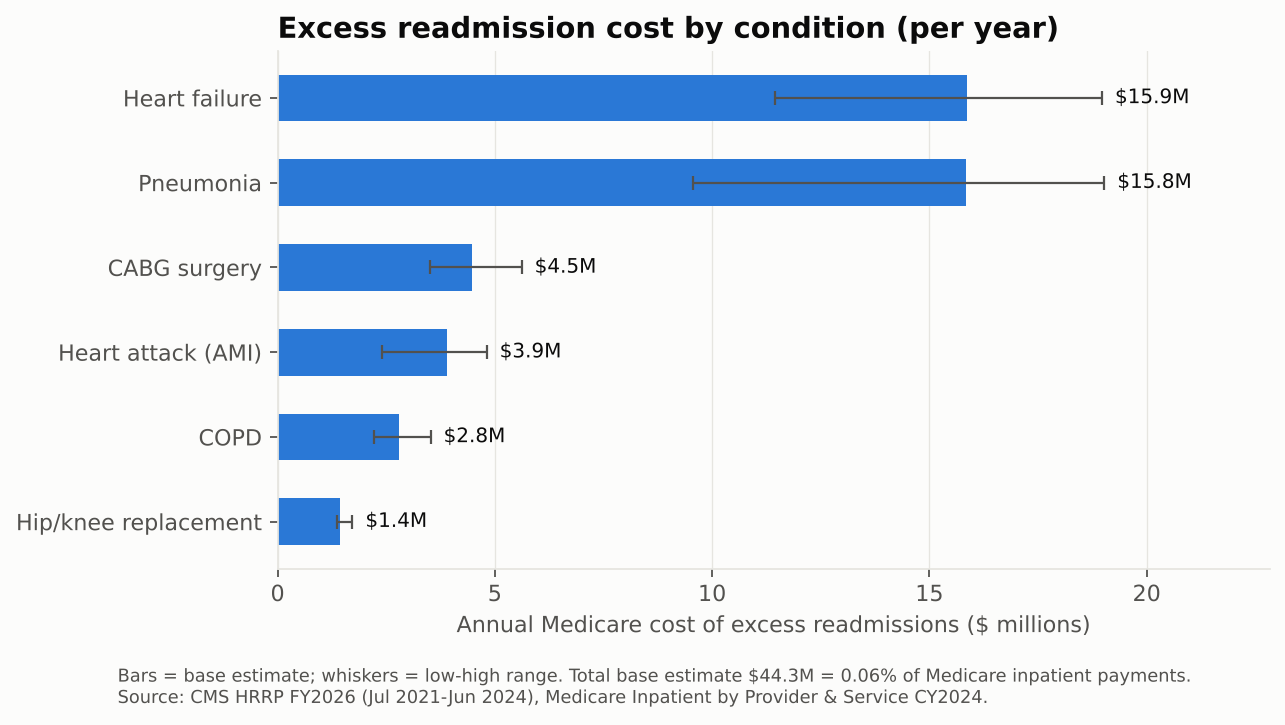

In [14]:
display(Image(ROOT / 'reports/figures/cost_by_condition.png'))

## c. High- vs low-volume hospitals
Top versus bottom quartile of Medicare discharges, comparing each hospital's average excess readmission ratio.
The **Mann-Whitney U** test is the primary test: the ratios are skewed and have outliers (see the Shapiro p-values) and the
groups have unequal variances. The effect size is the **rank-biserial correlation**. Welch's t-test and Cohen's d are a robustness check.

In [15]:
c = A.volume_vs_readmissions(t)
pd.Series({k: v for k, v in c.items() if not k.startswith('_') and not isinstance(v, (pd.DataFrame, dict))})

n_high                                       698
n_low                                        702
median_err_high                           0.9983
median_err_low                            0.9943
mean_err_high                             1.0003
mean_err_low                              0.9942
sd_err_high                               0.0568
sd_err_low                                0.0596
mann_whitney_u                      257,628.0000
mann_whitney_p                            0.0950
rank_biserial                             0.0516
hodges_lehmann_shift                      0.0043
median_diff_boot_ci95      [-0.001662, 0.011322]
welch_t                                   1.9595
welch_p                                   0.0503
cohens_d                                  0.1047
levene_p                                  0.0012
shapiro_p_high                            0.0403
shapiro_p_low                             0.0000
spearman_rho_volume_err                   0.0535
spearman_p          

In [16]:
c['per_condition']

,condition,n_high,n_low,median_err_high,median_err_low,p_value,rank_biserial,p_holm
0,Heart attack (AMI),684,67,0.9992,0.9908,0.6278,0.0359,0.6278
1,COPD,693,321,0.9984,0.9943,0.1702,0.0535,0.3404
2,Heart failure,697,552,0.9885,0.9973,0.0040,-0.0947,0.0201
3,Hip/knee replacement,575,155,1.0002,0.9680,0.0757,0.0929,0.2270
4,Pneumonia,697,623,0.9953,0.9880,0.0214,0.0733,0.0856


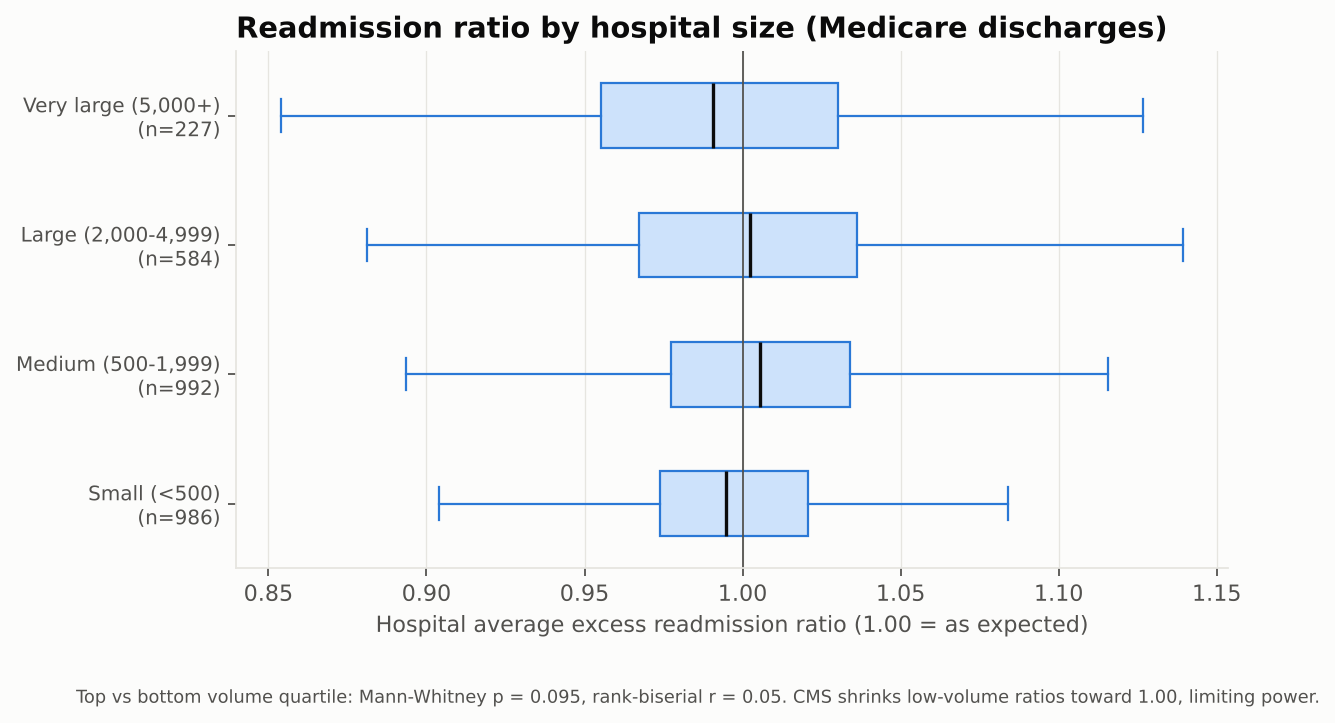

In [17]:
display(Image(ROOT / 'reports/figures/readmission_ratio_by_size.png'))

## d. Savings scenario
**N** is the smallest number of hospitals that together account for 50% of Medicare discharges.

`annual saving = 10% x SUM over top-N hospitals and conditions of max(excess readmissions per year, 0) x cost per readmission`

In [18]:
d = A.savings_scenario(t)
pd.Series(d['main'])

hospitals                              402.0000
hospitals_with_positive_excess         354.0000
positive_excess_readmissions         1,675.5922
avoided_readmissions                   167.5592
saving_low                       1,327,694.8433
saving_base                      1,920,837.5549
saving_high                      2,389,168.9626
top_n                                  402.0000
reduction                                0.1000
top_n_share_of_hospitals                 0.1383
top_n_share_of_discharges                0.5002
top_n_min_discharges                 3,680.0000
top_n_share_of_excess_cost               0.4336
dtype: float64

In [19]:
d['sensitivity'].map(lambda v: f'${v:,.0f}')

reduction,5%,10%,20%,100%
N,,,,
50,"$199,490","$398,979","$797,958","$3,989,791"
100,"$369,207","$738,415","$1,476,830","$7,384,149"
250,"$711,170","$1,422,341","$2,844,682","$14,223,408"
402,"$960,419","$1,920,838","$3,841,675","$19,208,376"
All,"$2,214,784","$4,429,567","$8,859,134","$44,295,672"


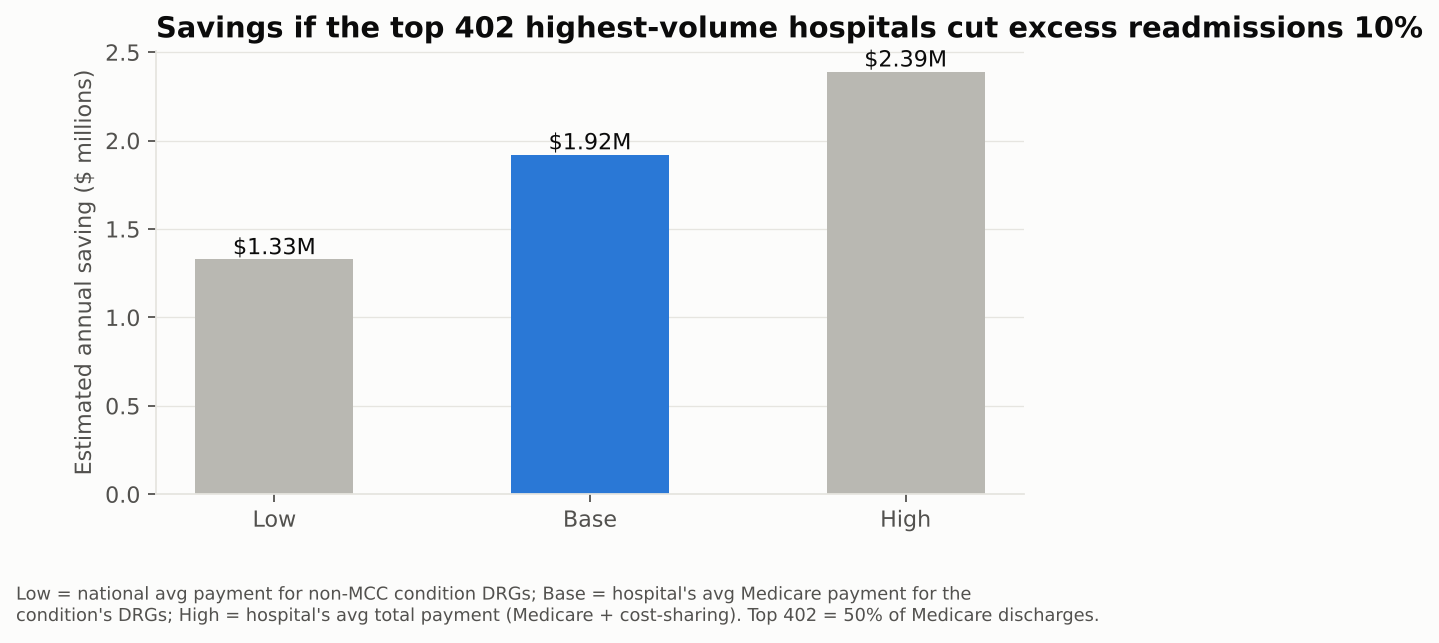

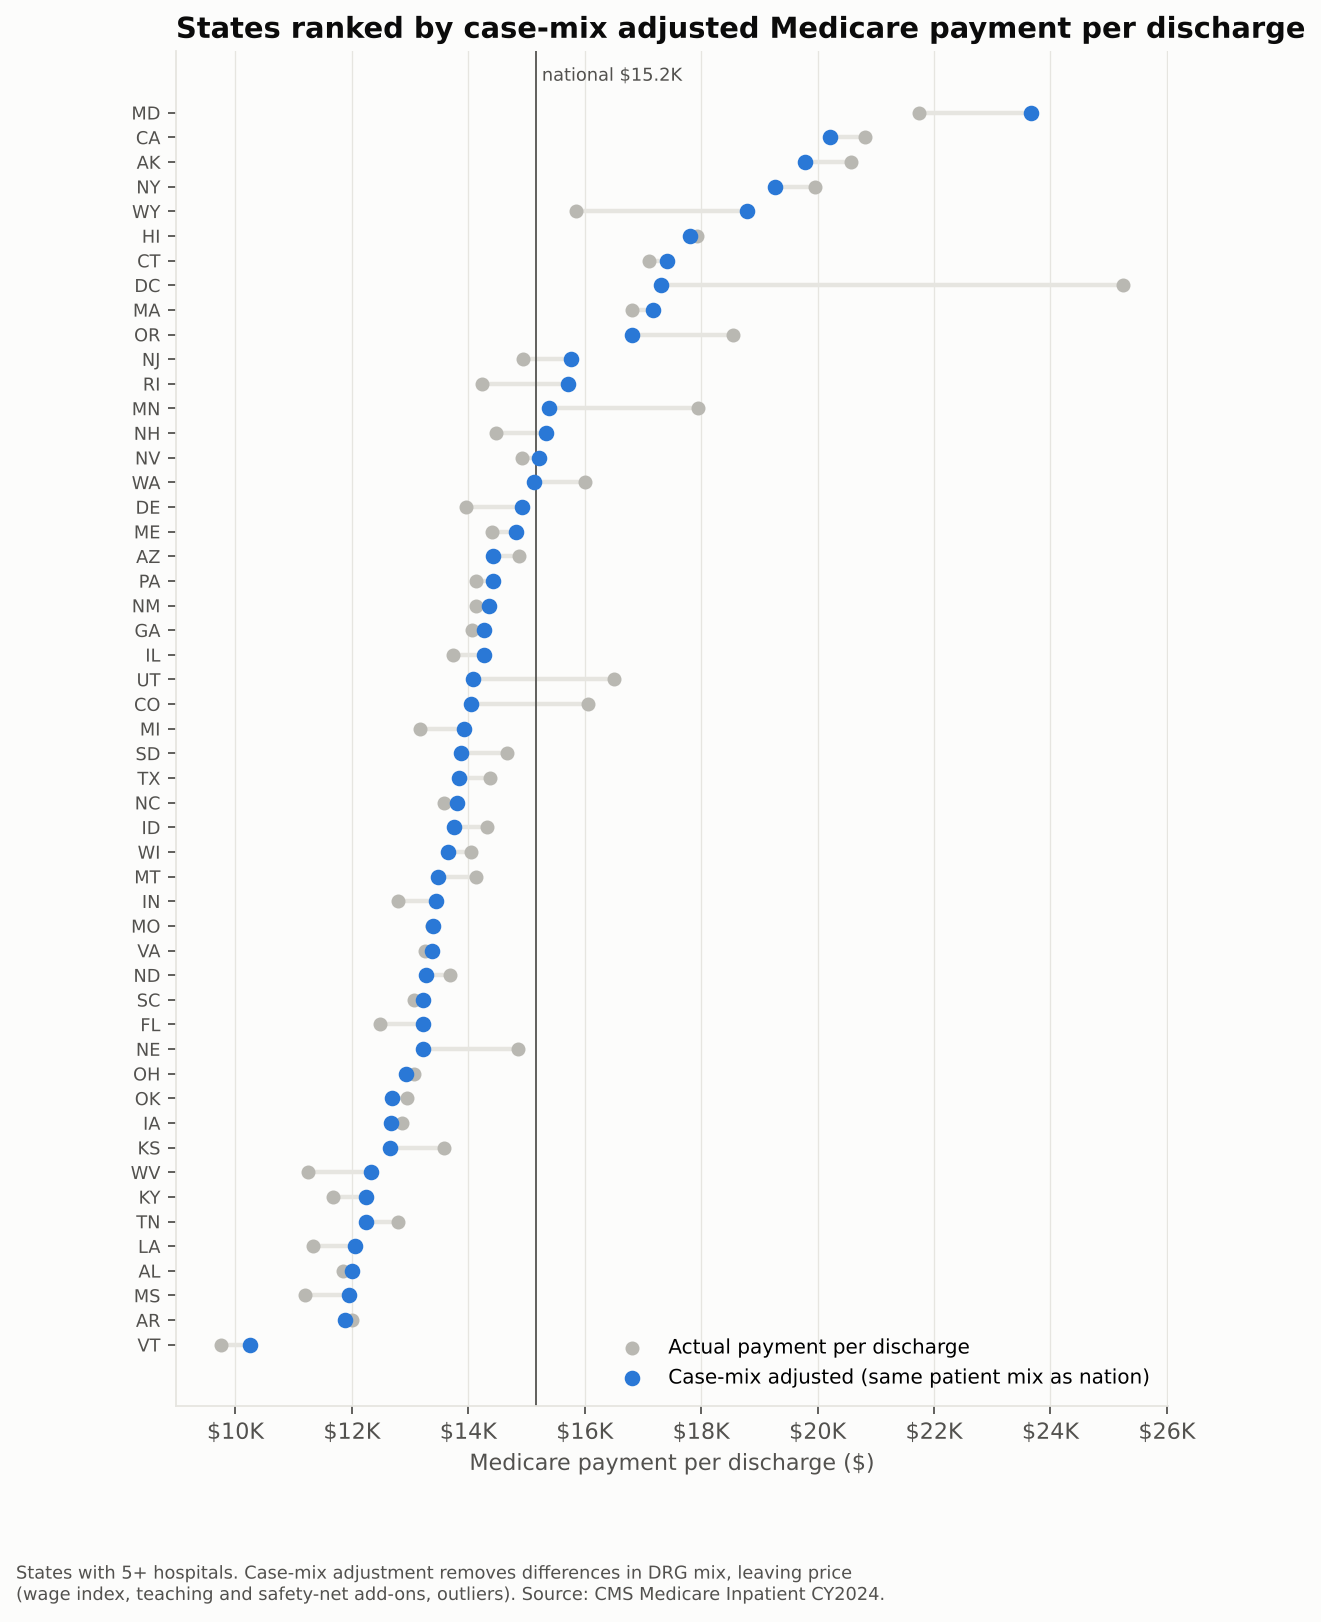

In [20]:
display(Image(ROOT / 'reports/figures/savings_scenario.png'))
display(Image(ROOT / 'reports/figures/state_ranking.png'))

## Conclusion
Excess readmissions are **not** a major Medicare cost driver. They are worth well under 0.1% of inpatient payments. Spending is driven by **case mix**
(sepsis DRG 871 alone is about 12% of payments) and **price/geography**. See `reports/FINDINGS.md` for the executive summary.